The usual machine-learning recipe is: collect a table of examples, split it at random into training and test sets, fit a model, report the test score. On financial time series every step of that recipe breaks:

- **Labels overlap.** “The return over the next month” for Monday and for Tuesday share 20 of their 21 days, so neighbouring examples are near-copies of each other.
- **Random splits leak.** If Tuesday is in the test set and Monday in the training set, the model has effectively seen the answer.
- **The signal is tiny and the world changes.** Chapter 1 showed how little a sample proves; adding a flexible model and many features makes it easy to fit noise.

This chapter builds the fixes from scratch, mostly following Marcos López de Prado's *Advances in Financial Machine Learning* (2018), and then uses them in a realistic project on SPY. The most important result is a negative one, and you will see it with your own eyes: the standard recipe reports skill on data that contains none.

:::eli5
Imagine a quiz where the questions are “what will the weather be over the next week?”, asked every day. Monday's answer and Tuesday's answer are almost the same week. If you study Monday's answer and are then tested on Tuesday's question, you will look like a brilliant forecaster without knowing anything. Purged cross-validation simply refuses to test you on days whose answers overlap with what you studied.
:::

## Setup and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path
from itertools import combinations
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss
from scipy import stats
import json, time, warnings
warnings.filterwarnings("ignore")

mpl.rc("axes", labelsize=12, titlesize=13); mpl.rc("figure", dpi=110)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
DATA = Path("datasets")
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}
rng = np.random.default_rng(42)

spy = pd.read_csv(DATA / "spy_ohlc.csv", index_col="date", parse_dates=True)
vix = pd.read_csv(DATA / "vix.csv", index_col="date", parse_dates=True)["VIXCLS"].reindex(spy.index).ffill()
close = spy["close"]
logp = np.log(close)
r = logp.diff()
print(spy.shape, spy.index[0].date(), "→", spy.index[-1].date())

(8497, 5) 1993-01-29 → 2026-10-30


## Labels: what exactly are we predicting?

### The fixed-horizon label and its problem

The most common label is the sign of the return over a fixed horizon $h$: $y_t = \operatorname{sign}(\ln P_{t+h} - \ln P_t)$. It ignores the path: a trade that falls 15% and recovers counts the same as one that rises smoothly, although no real trader would have held through the fall. It also ignores volatility: a +0.1% month in a calm market and in a crisis get the same label.

### The triple-barrier method

:::math
For each starting day $t$, set three barriers on the cumulative log return $R_{t,j} = \ln P_{t+j} - \ln P_t$:

- an **upper** barrier at $+k_u w_t$ (take profit) and a **lower** barrier at $-k_d w_t$ (stop loss), where $w_t = \hat\sigma_t\sqrt{h}$ scales with current volatility $\hat\sigma_t$;
- a **vertical** barrier at $j = h$ (maximum holding time).

The label is $+1$ if the upper barrier is touched first, $-1$ if the lower one is touched first, and the sign of $R_{t,h}$ if neither is touched. The label's **end time** $t_1$ is when the first barrier is touched. Labels now reflect what a disciplined trader would have experienced.
:::

In [2]:
def triple_barrier(logp, vol, h=21, k_up=1.0, k_dn=1.0):
    """Vectorised triple-barrier labels. Returns DataFrame with label, end position t1 and return."""
    L = logp.to_numpy(); n = len(L)
    fwd = sliding_window_view(L[1:], h)[: n - h] - L[: n - h, None]       # fwd[t, j-1] = R_{t,j}, j = 1..h
    w = (vol.to_numpy()[: n - h] * np.sqrt(h))[:, None]
    up, dn = fwd >= k_up * w, fwd <= -k_dn * w
    first_up = np.where(up.any(1), up.argmax(1), h)                        # index of first touch, h if never
    first_dn = np.where(dn.any(1), dn.argmax(1), h)
    hit = np.minimum(first_up, first_dn)
    label = np.where(first_up < first_dn, 1, np.where(first_dn < first_up, -1, np.sign(fwd[:, -1])))
    end = np.arange(n - h) + np.minimum(hit, h - 1) + 1                   # position of the end day
    ret = fwd[np.arange(n - h), np.minimum(hit, h - 1)]
    out = pd.DataFrame({"label": label.astype(int), "t1": end, "ret": ret, "barrier": np.where(hit < h, "horizontal", "vertical")},
                       index=logp.index[: n - h])
    return out[np.isfinite(w[:, 0])]

vol_d = r.ewm(span=50).std()
lab = triple_barrier(logp, vol_d, h=21, k_up=1.0, k_dn=1.0).loc["1994":]
print(lab["label"].value_counts(normalize=True).round(3).to_dict())
print(lab["barrier"].value_counts(normalize=True).round(3).to_dict())
print("average holding days:", (lab["t1"] - np.arange(len(r))[r.index.get_indexer(lab.index)]).mean().round(1))
R["share_up"] = f"{(lab['label'] == 1).mean():.0%}"

{1: 0.636, -1: 0.364, 0: 0.0}
{'vertical': 0.529, 'horizontal': 0.471}
average holding days: 17.0


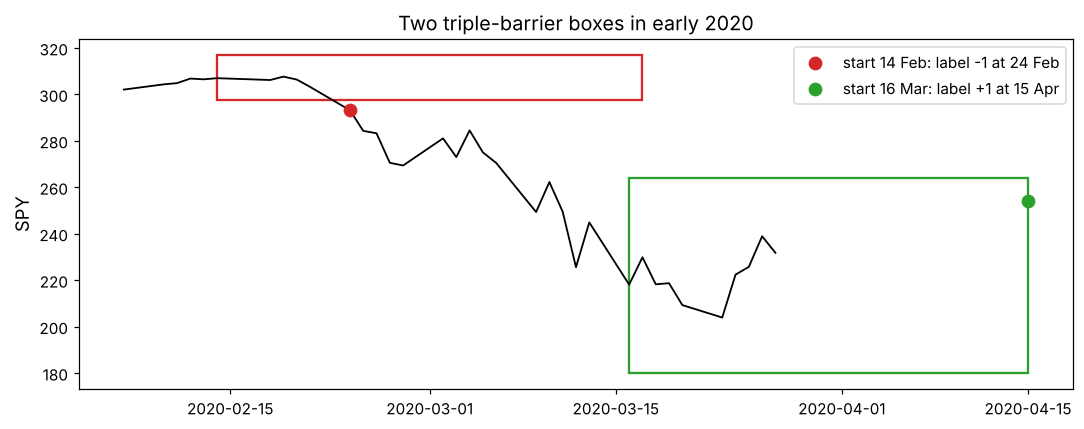

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
t0 = close.index.get_loc(pd.Timestamp("2020-02-14"))
seg = close.iloc[t0 - 5: t0 + 30]
ax.plot(seg, "k", lw=1.2)
for k, col in [(t0, "tab:red"), (t0 + 20, "tab:green")]:
    d0 = close.index[k]; w0 = vol_d.iloc[k] * np.sqrt(21); p0 = close.iloc[k]
    t_end = close.index[min(k + 21, len(close) - 1)]
    ax.add_patch(plt.Rectangle((d0, p0 * np.exp(-w0)), t_end - d0, p0 * (np.exp(w0) - np.exp(-w0)), fill=False, ec=col, lw=1.5))
    row = lab.loc[d0]
    ax.plot(close.index[int(row.t1)], close.iloc[int(row.t1)], "o", color=col, ms=8,
            label=f"start {d0:%d %b}: label {int(row.label):+d} at {close.index[int(row.t1)]:%d %b}")
ax.legend(); ax.set_ylabel("SPY"); ax.set_title("Two triple-barrier boxes in early 2020")
save_fig("triple_barrier"); plt.show()

![Figure 5-1. Each box is one label: its height is ±1 volatility-scaled width, its length the 21-day vertical barrier. The dot marks the first barrier touched.](images/triple_barrier.png)

## Overlapping labels and sample uniqueness

Each label covers the days from $t+1$ to $t_1$. With one label per day and a horizon of about 21 days, around twenty labels are “alive” on any given day.

:::math
The **concurrency** of day $s$ is $c_s = \#\{i : t_i < s \leq t_{1,i}\}$, the number of labels whose returns include day $s$. The **average uniqueness** of label $i$ is

$$\bar u_i = \frac{1}{t_{1,i} - t_i}\sum_{s = t_i + 1}^{t_{1,i}} \frac{1}{c_s},$$

the share of its returns that it does not share with other labels. The sum $\sum_i \bar u_i$ is an **effective number of independent samples**. Using $\bar u_i$ as a sample weight stops the model from over-counting periods covered by many near-identical labels.
:::

In [4]:
def uniqueness(start_pos, end_pos, n):
    conc = np.zeros(n + 1)
    np.add.at(conc, start_pos + 1, 1); np.add.at(conc, end_pos + 1, -1)
    conc = np.cumsum(conc)[:n]                                    # labels alive on each day
    inv = np.r_[0, np.cumsum(1 / np.where(conc > 0, conc, np.inf))]
    return (inv[end_pos + 1] - inv[start_pos + 1]) / (end_pos - start_pos), conc

start_pos = close.index.get_indexer(lab.index)
u, conc = uniqueness(start_pos, lab["t1"].to_numpy(), len(close))
lab["uniq"] = u
print(f"{len(lab):,} labels; average uniqueness {u.mean():.3f}; effective independent samples ≈ {u.sum():,.0f}")
R["n_lab"] = f"{len(lab):,}"; R["u_mean"] = f"{u.mean():.3f}"; R["n_eff"] = f"{u.sum():,.0f}"

8,242 labels; average uniqueness 0.062; effective independent samples ≈ 508


We have 8,242 labels, but their average uniqueness is only 0.062: they are worth about 508 independent observations. Every statistic that treats the labels as independent overstates its precision by a factor of about $\sqrt{1/\bar u}$.

## Cross-validation that does not leak

### A test on data with no signal at all

Here is the experiment that should change how you validate forever. We simulate a **pure random walk**: by construction nothing about the future is predictable. We compute ordinary-looking features (past returns and volatility over several windows) and the 21-day forward direction as the label, and score a random forest with three kinds of cross-validation.

In [5]:
def make_features(logp, r, vix=None):
    f = pd.DataFrame(index=logp.index)
    for k in [5, 21, 63, 126, 252]:
        f[f"ret_{k}"] = logp.diff(k)
    for k in [21, 63]:
        f[f"vol_{k}"] = r.rolling(k).std() * np.sqrt(252)
    f["vol_ratio"] = f["vol_21"] / f["vol_63"]
    f["dist_ma200"] = logp - logp.rolling(200).mean()
    f["drawdown_252"] = logp - logp.rolling(252).max()
    if vix is not None:
        f["vix"] = vix; f["vix_chg_5"] = np.log(vix).diff(5); f["vrp"] = (vix / 100) - f["vol_21"]
    return f

n_sim = len(close)
sim_r = pd.Series(rng.normal(0.0003, 0.012, n_sim), index=close.index)
sim_logp = sim_r.cumsum()
Xs = make_features(sim_logp, sim_r)
ys = np.sign(sim_logp.shift(-21) - sim_logp)                     # forward 21-day direction: unpredictable by construction
sim = Xs.join(ys.rename("y")).dropna().iloc[:-21]
sim_start = np.arange(len(sim)); sim_end = sim_start + 21         # each label ends 21 days later
print(sim.shape, "share of up labels:", round((sim["y"] > 0).mean(), 3))

(8203, 11) share of up labels: 0.527


Three ways to cross-validate:

1. **Shuffled K-fold:** the textbook default; test days are scattered among training days.
2. **Ordered K-fold:** contiguous blocks of time, but training data still touches the test block at its edges.
3. **Purged K-fold with embargo:** contiguous blocks; remove from training every example whose label period overlaps the test block (*purging*), plus a short buffer after the test block (*embargo*) because features such as moving averages also carry information across the boundary.

In [6]:
def purged_kfold(start_t, end_t, n_splits=5, embargo=0):
    """Yield (train, test) row indices. Samples are sorted in time; start_t[i] and end_t[i] are the
    positions, on one common trading calendar, of the first and last day that label i depends on."""
    start_t, end_t = np.asarray(start_t), np.asarray(end_t)
    idx = np.arange(len(start_t))
    for test in np.array_split(idx, n_splits):                   # contiguous blocks of time
        t_lo, t_hi = start_t[test].min(), end_t[test].max()
        overlap = (end_t >= t_lo) & (start_t <= t_hi)            # purge: label span intersects the test span
        embargoed = (start_t > t_hi) & (start_t <= t_hi + embargo)   # embargo: just after the test span
        yield idx[~overlap & ~embargoed], test

def cv_score(X, y, splitter, weights=None, model=None):
    if model is None:                                            # (not `model or ...`: sklearn ensembles define len())
        model = RandomForestClassifier(n_estimators=200, min_samples_leaf=50, max_features="sqrt", n_jobs=-1, random_state=0)
    acc, auc, oof = [], [], np.full(len(y), np.nan)
    for tr, te in splitter:
        kw = {}
        if weights is not None:                                   # a Pipeline routes weights to its last step
            kw[(model.steps[-1][0] + "__" if hasattr(model, "steps") else "") + "sample_weight"] = weights[tr]
        model.fit(X[tr], y[tr], **kw)
        p = model.predict_proba(X[te])[:, 1]
        oof[te] = p
        acc.append(accuracy_score(y[te], p > 0.5)); auc.append(roc_auc_score(y[te], p))
    return np.mean(acc), np.mean(auc), oof

Xa, ya = sim.drop(columns="y").to_numpy(), (sim["y"] > 0).astype(int).to_numpy()
schemes = {
    "shuffled K-fold": KFold(5, shuffle=True, random_state=0).split(Xa),
    "ordered K-fold": KFold(5, shuffle=False).split(Xa),
    "purged + embargo": purged_kfold(sim_start, sim_end, 5, embargo=63),
}
leak = {}
for name, sp in schemes.items():
    a, au, _ = cv_score(Xa, ya, sp)
    leak[name] = (a, au); print(f"{name:18s} accuracy {a:.3f}   AUC {au:.3f}")
R["leak_acc"] = f"{leak['shuffled K-fold'][0]:.1%}"; R["leak_auc"] = f"{leak['shuffled K-fold'][1]:.2f}"
R["purge_acc"] = f"{leak['purged + embargo'][0]:.1%}"; R["purge_auc"] = f"{leak['purged + embargo'][1]:.2f}"

shuffled K-fold    accuracy 0.701   AUC 0.776


ordered K-fold     accuracy 0.478   AUC 0.479


purged + embargo   accuracy 0.478   AUC 0.480


On a random walk, where the true accuracy of *any* model is 50% (or the share of up days), **shuffled K-fold reports 70.1% accuracy and an AUC of 0.78**. Purged cross-validation with an embargo reports 47.8% and 0.48: the truth, no better than guessing. Shuffled cross-validation did not discover a signal; it discovered that neighbouring days have similar features and share most of their future. A research team using it would be fooled every time. Ordered (unshuffled) folds already remove most of the leak here, because only the edges of each fold touch the training data; purging removes the rest, which matters more with longer horizons, more folds, or the combinatorial splits used later in this chapter.

::playground animations/cv_lab.html 640

The playground's **Purge & embargo** tab draws the label spans and shows exactly which training samples are removed around a test fold.

:::trap
Leakage hides in more places than the split: features computed on the whole sample (scaling with the full-sample mean, filling with `bfill`), targets that overlap features (a 21-day return target with a 21-day volatility feature that ends on the same day is fine; one that *starts* on the same day is not), and hyper-parameters tuned on the test folds. Purging handles the overlap of labels; the rest needs discipline.
:::

## Project: predicting SPY's direction honestly

Now real data. Features: returns over five horizons, two volatilities and their ratio, the distance from the 200-day average, the drawdown from the one-year high, and three VIX features (level, 5-day change, and the gap between implied and realised volatility). Label: the triple-barrier label above. Weights: average uniqueness.

In [7]:
F = make_features(logp, r, vix)
data = F.join(lab[["label", "t1", "ret", "uniq"]], how="inner").dropna()
X = data[F.columns].to_numpy(); y = (data["label"] > 0).astype(int).to_numpy()
w = data["uniq"].to_numpy()
start_t = close.index.get_indexer(data.index)                  # calendar positions of label starts
end_t = data["t1"].to_numpy()                                    # ... and of label ends
print(X.shape, "base rate (share up):", round(y.mean(), 3))

models = {
    "always up": None,
    "logistic": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000)),
    "random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=100, max_features="sqrt", n_jobs=-1, random_state=0),
}
rows, oofs = [], {}
for name, mdl in models.items():
    if mdl is None:
        p = np.full(len(y), y.mean()); rows.append({"model": name, "accuracy": max(y.mean(), 1 - y.mean()), "AUC": 0.5,
                                                  "log loss": log_loss(y, p)}); oofs[name] = p; continue
    for scheme in ["shuffled", "purged"]:
        sp = KFold(5, shuffle=True, random_state=0).split(X) if scheme == "shuffled" else purged_kfold(start_t, end_t, 5, embargo=63)
        a, au, oof = cv_score(X, y, sp, weights=w, model=mdl)
        rows.append({"model": f"{name} ({scheme} CV)", "accuracy": a, "AUC": au, "log loss": log_loss(y, np.clip(oof, 1e-6, 1 - 1e-6))})
        oofs[f"{name} ({scheme})"] = oof
real = pd.DataFrame(rows).set_index("model")
print(real.round(4))
R["rf_sh_auc"] = f"{real.loc['random forest (shuffled CV)', 'AUC']:.2f}"; R["rf_pu_auc"] = f"{real.loc['random forest (purged CV)', 'AUC']:.2f}"
R["lr_pu_auc"] = f"{real.loc['logistic (purged CV)', 'AUC']:.2f}"; R["base_acc"] = f"{max(y.mean(), 1 - y.mean()):.1%}"
R["rf_pu_acc"] = f"{real.loc['random forest (purged CV)', 'accuracy']:.1%}"

(8224, 13) base rate (share up): 0.636


                             accuracy     AUC  log loss
model                                                  
always up                      0.6358  0.5000    0.6558
logistic (shuffled CV)         0.6348  0.5221    0.6559
logistic (purged CV)           0.6187  0.4647    0.6663
random forest (shuffled CV)    0.6656  0.7053    0.6098
random forest (purged CV)      0.6243  0.5182    0.6656


The same split between fiction and reality appears on real data: the random forest's AUC is 0.71 with shuffled folds but 0.52 with purged folds; the logistic regression reaches 0.46. Simply predicting “up” every time is right 63.6% of the time, and the purged random forest is right 62.4%. Predicting the direction of the index from its own price history and the VIX is close to impossible, as Chapter 1 warned. That is not a failure of the method; it is the method doing its job.

## Meta-labelling: let ML size the bet, not choose the side

López de Prado's most practical idea. Keep a simple, economically motivated **primary** rule that decides the side (here: be long SPY when it is above its 200-day average, the rule from Chapter 2), and train a **secondary** model only to answer: *given that the primary rule says buy, how likely is this trade to work?* Its probability then sizes the position. The secondary model's task is easier (it only sees the cases the primary rule selected) and its errors are less costly (it can only shrink or skip trades).

In [8]:
primary = (logp > logp.rolling(200).mean()).reindex(data.index)            # 1 = primary says long
events = data[primary.astype(bool)]
Xm, ym, wm = events[F.columns].to_numpy(), (events["label"] > 0).astype(int).to_numpy(), events["uniq"].to_numpy()
mdl = RandomForestClassifier(n_estimators=300, min_samples_leaf=100, max_features="sqrt", n_jobs=-1, random_state=0)
a, au, p_meta = cv_score(Xm, ym, purged_kfold(close.index.get_indexer(events.index), events["t1"].to_numpy(), 5, embargo=63), weights=wm, model=mdl)
print(f"meta-model on {len(events):,} primary-long days: accuracy {a:.3f}, AUC {au:.3f}, primary hit rate {ym.mean():.3f}")

# turn probabilities into position sizes and backtest daily: decide at the close, hold the next day
size = pd.Series(0.0, index=data.index)
size.loc[events.index] = np.clip(2 * p_meta - 1, 0, 1)                # bet size from the probability
nxt = np.exp(r.shift(-1)).reindex(data.index) - 1
strategies = {"buy and hold": pd.Series(1.0, index=data.index), "primary (200-day rule)": primary.astype(float),
              "primary × meta size": size}
def sharpe(x): return x.mean() / x.std() * np.sqrt(252)
mt = pd.DataFrame({k: {"Sharpe": sharpe((s * nxt).dropna()), "avg exposure": s.mean(),
                       "max DD": ((1 + (s * nxt).dropna()).cumprod() / (1 + (s * nxt).dropna()).cumprod().cummax() - 1).min()}
                   for k, s in strategies.items()}).T
print(mt.round(3))
R["meta_auc"] = f"{au:.2f}"; R["sh_prim"] = f"{mt.loc['primary (200-day rule)', 'Sharpe']:.2f}"; R["sh_meta"] = f"{mt.loc['primary × meta size', 'Sharpe']:.2f}"
R["sh_bh5"] = f"{mt.loc['buy and hold', 'Sharpe']:.2f}"

meta-model on 6,367 primary-long days: accuracy 0.644, AUC 0.504, primary hit rate 0.654
                        Sharpe  avg exposure  max DD
buy and hold             0.643         1.000  -0.552
primary (200-day rule)   0.740         0.774  -0.289
primary × meta size      0.609         0.241  -0.138


The meta-model's purged AUC is 0.50: it cannot tell the primary rule's good trades from its bad ones. Used to size positions anyway, it *lowers* the Sharpe ratio from 0.74 (the 200-day rule alone, itself better than buy and hold at 0.64) to 0.61, because sizing by a noisy probability adds noise. This is an honest negative result, and an important one: meta-labelling is a way to *use* information about when a rule works, not a way to *create* it. It helps when the secondary features carry information the primary rule ignores (for example earnings dates, flows, cross-asset signals or order-book data for an intraday rule); SPY's own price history and the VIX do not. Purged validation is what told us so before any money was at risk.

## Feature importance, honestly

Feature importance tells you *what the model is using*, which is the best check that it learned something economically sensible rather than an artefact.

- **MDI** (mean decrease in impurity): the random forest's built-in importance. Fast, but computed on the training data and biased towards features with many distinct values.
- **MDA** (mean decrease in accuracy, also called permutation importance): shuffle one feature in the *test* folds and measure how much the out-of-sample score drops.
- **SFI** (single-feature importance): the purged cross-validated score of a model that uses only that feature. Immune to the substitution effect, where two correlated features share (and dilute) their importance.

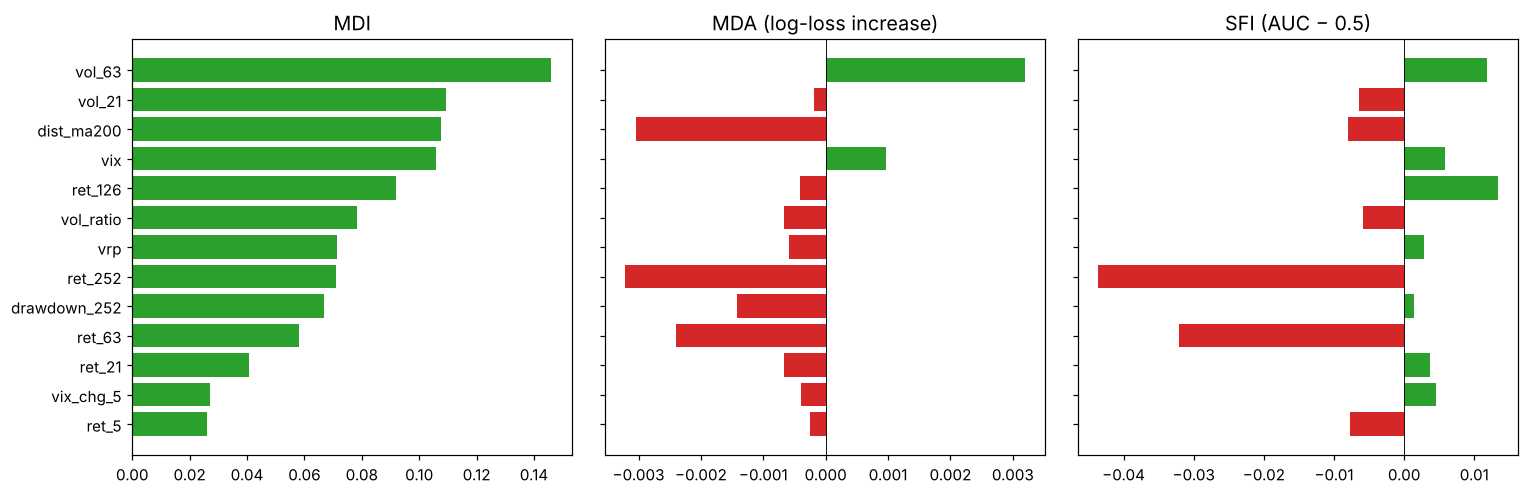

In [9]:
names = list(F.columns)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=100, max_features="sqrt", n_jobs=-1, random_state=0)
mdi = pd.Series(rf.fit(X, y, sample_weight=w).feature_importances_, index=names)

def mda(X, y, w, start_t, end_t, n_splits=5, reps=3):
    drops = np.zeros(X.shape[1]); rng_ = np.random.default_rng(1)
    for tr, te in purged_kfold(start_t, end_t, n_splits, embargo=63):
        m = RandomForestClassifier(n_estimators=200, min_samples_leaf=100, max_features="sqrt", n_jobs=-1, random_state=0).fit(X[tr], y[tr], sample_weight=w[tr])
        base = log_loss(y[te], m.predict_proba(X[te])[:, 1], labels=[0, 1])
        for j in range(X.shape[1]):
            for _ in range(reps):
                Xp = X[te].copy(); Xp[:, j] = rng_.permutation(Xp[:, j])
                drops[j] += (log_loss(y[te], m.predict_proba(Xp)[:, 1], labels=[0, 1]) - base) / (n_splits * reps)
    return pd.Series(drops, index=names)

def sfi(X, y, w, start_t, end_t):
    out = {}
    for j, nm in enumerate(names):
        m = RandomForestClassifier(n_estimators=100, min_samples_leaf=100, n_jobs=-1, random_state=0)
        out[nm] = cv_score(X[:, [j]], y, purged_kfold(start_t, end_t, 5, embargo=63), weights=w, model=m)[1] - 0.5
    return pd.Series(out)

imp = pd.DataFrame({"MDI": mdi, "MDA (log-loss increase)": mda(X, y, w, start_t, end_t), "SFI (AUC − 0.5)": sfi(X, y, w, start_t, end_t)})
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
order = imp["MDI"].sort_values().index
for ax, col in zip(axes, imp.columns):
    vals = imp.loc[order, col]
    ax.barh(order, vals, color=["tab:green" if v > 0 else "tab:red" for v in vals]); ax.axvline(0, color="k", lw=0.6); ax.set_title(col)
save_fig("feature_importance"); plt.show()
R["top_mdi"] = imp["MDI"].idxmax(); R["top_sfi"] = imp["SFI (AUC − 0.5)"].idxmax(); R["n_mda_pos"] = int((imp["MDA (log-loss increase)"] > 0).sum())

![Figure 5-2. Three views of feature importance for the SPY model. MDI (in-sample) always looks informative; MDA and SFI (out-of-sample, purged) show how little survives.](images/feature_importance.png)

MDI ranks **vol_63** first, but MDI is always positive, even for pure noise. Out of sample, only 2 of the features make the purged log loss worse when shuffled, and the single most useful feature on its own is **ret_126**. When MDI and MDA disagree, believe MDA: it is measured where it matters.

## How likely is your best backtest to be overfit?

Chapter 1 deflated the Sharpe ratio of the best of many trials. Bailey, Borwein, López de Prado and Zhu (2017) proposed a direct, model-free estimate of the **probability of backtest overfitting** (PBO) with **combinatorially symmetric cross-validation** (CSCV).

:::math
Take the daily returns of $N$ strategy variants, a matrix of $T \times N$. Split the $T$ rows into $S$ equal blocks (say 16). For each of the $\binom{S}{S/2}$ ways of choosing half of the blocks as “in sample”:

1. find the variant with the best in-sample Sharpe ratio;
2. compute its rank among all variants in the other half, out of sample, as a relative rank $\omega \in (0, 1)$ and its logit $\lambda = \ln\frac{\omega}{1 - \omega}$.

**PBO** is the share of splits in which the in-sample winner ranks *below the median* out of sample ($\lambda \leq 0$). A PBO near 0.5 or above means that selecting the best backtest is no better than picking at random.
:::

(8010, 59)


PBO = 0.87 over 12,870 splits (30 s)


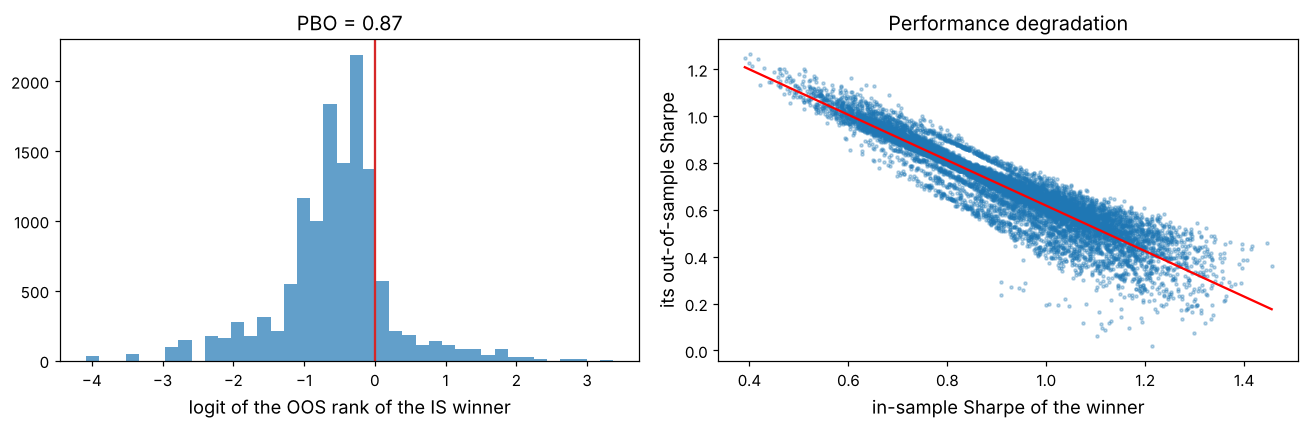

In [10]:
# moving-average crossover variants on SPY: fast in 5..50, slow in 50..250
fasts, slows = [5, 10, 20, 30, 40, 50], [50, 75, 100, 125, 150, 175, 200, 225, 250, 300]
nxt_all = np.exp(r.shift(-1)) - 1
M = pd.DataFrame({f"{f}/{s}": ((close.rolling(f).mean() > close.rolling(s).mean()).astype(float) * nxt_all)
                  for f in fasts for s in slows if f < s}).loc["1995":].dropna()
print(M.shape); R["n_var"] = M.shape[1]

def pbo_cscv(M, S=16):
    X_ = M.to_numpy(); T, N = X_.shape
    blocks = np.array_split(np.arange(T), S)
    sr = lambda A: A.mean(0) / A.std(0)
    lam, is_best, oos_best = [], [], []
    for ins in combinations(range(S), S // 2):
        i_idx = np.concatenate([blocks[k] for k in ins])
        o_idx = np.concatenate([blocks[k] for k in range(S) if k not in ins])
        sr_in, sr_out = sr(X_[i_idx]), sr(X_[o_idx])
        n_star = np.argmax(sr_in)
        rank = stats.rankdata(sr_out)[n_star]
        omega = rank / (N + 1)
        lam.append(np.log(omega / (1 - omega))); is_best.append(sr_in[n_star]); oos_best.append(sr_out[n_star])
    lam = np.array(lam)
    return (lam <= 0).mean(), lam, np.array(is_best) * np.sqrt(252), np.array(oos_best) * np.sqrt(252)

t0 = time.perf_counter()
pbo, lam, sr_is, sr_oos = pbo_cscv(M)
print(f"PBO = {pbo:.2f} over {len(lam):,} splits ({time.perf_counter() - t0:.0f} s)")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(lam, bins=40, alpha=0.7); ax[0].axvline(0, color="tab:red"); ax[0].set_xlabel("logit of the OOS rank of the IS winner"); ax[0].set_title(f"PBO = {pbo:.2f}")
ax[1].scatter(sr_is, sr_oos, s=4, alpha=0.3); ax[1].set_xlabel("in-sample Sharpe of the winner"); ax[1].set_ylabel("its out-of-sample Sharpe")
b = np.polyfit(sr_is, sr_oos, 1); xs_ = np.linspace(sr_is.min(), sr_is.max(), 10); ax[1].plot(xs_, np.polyval(b, xs_), "r")
ax[1].set_title("Performance degradation")
save_fig("pbo"); plt.show()
R["pbo"] = f"{pbo:.2f}"; R["deg_slope"] = f"{b[0]:+.2f}"; R["is_mean"] = f"{sr_is.mean():.2f}"; R["oos_mean"] = f"{sr_oos.mean():.2f}"

![Figure 5-3. Left: distribution of the logit of the out-of-sample rank of the in-sample winner across 12,870 splits. Right: the in-sample Sharpe ratio of the winner against its out-of-sample Sharpe ratio.](images/pbo.png)

For 59 moving-average variants on SPY, PBO is 0.87: in most splits the in-sample winner ranks in the *bottom* half out of sample. The winners averaged a Sharpe ratio of 0.91 in sample but 0.70 out of sample, and the slope of out-of-sample on in-sample Sharpe is -0.97: the better a variant looked in sample, the worse it tended to do out of sample. Relative performance among these variants mean-reverts, because each one is mostly the same bet (being long the market most of the time) plus luck about the exact timing of a few big moves. The out-of-sample Sharpe ratios are still positive, but that comes from the market exposure all the variants share, not from the skill of choosing among them.

## The checklist

| Step | Standard ML | Financial ML done right |
|---|---|---|
| Label | fixed horizon | triple barrier, volatility-scaled; record each label's end time |
| Sample weights | none | average uniqueness (overlap) |
| Validation | shuffled K-fold | purged K-fold with embargo; walk-forward for the final test |
| Model | maximise accuracy | prefer simple models; check against “always up” and log loss |
| Use of the model | predict the side | meta-label a primary rule; size bets by probability |
| Importance | MDI | MDA and SFI under purged CV |
| Many backtests | report the best | count the trials; deflated Sharpe; PBO |

## Exercises

:::exercise
1. Repeat the random-walk experiment with an embargo of 0. How much leakage remains from purging alone? Why do features such as `dist_ma200` need an embargo?
2. Change the triple barrier to $k_u = 2, k_d = 1$ (a wider profit target than stop loss). How does the share of positive labels change, and what does that do to the base rate a model must beat?
3. Train the SPY model on the fixed-horizon label instead. Compare purged AUCs.
4. Compute PBO for 60 random-signal strategies (coin flips). What value do you expect, and what do you get?
5. Implement the **sequential bootstrap** (López de Prado, ch. 4): draw labels with probability proportional to their uniqueness *given the labels already drawn*, and compare the average uniqueness of a sequential and a standard bootstrap sample.
:::

<details><summary>Solutions</summary>

In [11]:
# 1
a0, au0, _ = cv_score(Xa, ya, purged_kfold(sim_start, sim_end, 5, embargo=0))
print(f"purged without embargo: accuracy {a0:.3f}, AUC {au0:.3f}")

# 2
lab2 = triple_barrier(logp, vol_d, h=21, k_up=2.0, k_dn=1.0).loc["1994":]
print("share up with k_up=2, k_dn=1:", round((lab2["label"] > 0).mean(), 3))

# 4
coins = pd.DataFrame(rng.choice([0.0, 1.0], size=(len(M), 60)) * nxt_all.reindex(M.index).to_numpy()[:, None], index=M.index)
print("PBO for one coin-flip matrix (S=16):", round(pbo_cscv(coins)[0], 2))
# one matrix gives a noisy estimate: the 12,870 splits all reuse the same data. Average over many matrices:
pbos = [pbo_cscv(pd.DataFrame(np.random.default_rng(s).choice([0.0, 1.0], size=(len(M), 60)) * nxt_all.reindex(M.index).to_numpy()[:, None]), S=10)[0]
        for s in range(20)]
print("average PBO over 20 coin-flip matrices (S=10):", round(np.mean(pbos), 2), "(theory for no skill: 0.5)")

purged without embargo: accuracy 0.478, AUC 0.479
share up with k_up=2, k_dn=1: 0.63


PBO for one coin-flip matrix (S=16): 0.26


average PBO over 20 coin-flip matrices (S=10): 0.52 (theory for no skill: 0.5)


</details>

## What's next

Predicting the market's direction from its own history is close to hopeless, and this chapter proved it honestly. The richer problem is *relative*: among hundreds of stocks, which will do better than the others next month? Chapter 6 moves to the cross-section, where the signal is weak but the number of independent bets is large, and where ML has a real chance.

In [12]:
Path("animations").mkdir(exist_ok=True)
print("playground uses no exported data")

playground uses no exported data
